# Q3. Exclusive time of function
On a single-threaded CPU, we execute a program containing n functions. Each function has a unique ID between 0 and n - 1.

Function calls are stored in a call stack: when a function call starts, its ID is pushed onto the stack, and when a function call ends, its ID is popped off the stack. The function whose ID is at the top of the stack is the current function being executed. Each time a function starts or ends, we write a log with the ID, whether it started or ended, and the timestamp.

You are given a list logs, where logs[i] represents the ith log message formatted as a string "{function_id}:{"start" | "end"}:{timestamp}". For example, "0:start:3" means a function call with function ID 0 started at the beginning of timestamp 3, and "1:end:2" means a function call with function ID 1 ended at the end of timestamp 2. Note that a function can be called multiple times, possibly recursively.

A function's exclusive time is the sum of execution times for all function calls in the program. For example, if a function is called twice, one call executing for 2 time units and another call executing for 1 time unit, the exclusive time is 2 + 1 = 3.

Return the exclusive time of each function in an array, where the value at the ith index represents the exclusive time for the function with ID i.

In [29]:
import java.util.Stack

fun Boolean.toInt() = if (this) 1 else 0

class Solution {
    fun exclusiveTime(n: Int, logs: List<String>): IntArray {

        val result = IntArray(n)
        val stack = Stack<Int>()

        for(i in 1..<logs.size){
            val operOneStart = logs[i-1].contains("start").toInt()
            val operSecondStart = logs[i].contains("start").toInt()

            val resultComb = operSecondStart * 10 + operOneStart

            val timeDiff = logs[i].slice(IntRange(logs[i].indexOfLast { it == ':' }+1, logs[i].length-1)).toInt() - logs[i-1].slice(IntRange(logs[i-1].indexOfLast { it == ':' }+1, logs[i-1].length-1)).toInt()

            when(resultComb){
                //00 - both ends
                0 -> {
                    val id = stack.pop()

                    result[id] += timeDiff

                    println("Logs:\n${logs[i-1]}\n${logs[i]}\nTimeDiff ${timeDiff}\nID^ ${id}")
                }
                //01 - second - end, first - start
                1 -> {
                    val id = logs[i].slice(IntRange(0, logs[i].indexOfFirst { it == ':' }-1)).toInt()

                    result[id] += timeDiff + 1
                    println("Logs:\n${logs[i-1]}\n${logs[i]}\nTimeDiff ${timeDiff}\nID^ ${id}")
                }
                //10 - second - start, first - end
                10 -> {
                    if (!stack.empty()){
                        val id = stack.last()

                        result[id] += timeDiff - 1
                        println("Logs:\n${logs[i-1]}\n${logs[i]}\nTimeDiff ${timeDiff}\nID^ ${id}")
                    }
                }
                //11 - both starts
                11 -> {
                    val id = logs[i-1].slice(IntRange(0, logs[i-1].indexOfFirst { it == ':' }-1)).toInt()

                    result[id] += timeDiff

                    stack.push(id)
                    println("Logs:\n${logs[i-1]}\n${logs[i]}\nTimeDiff ${timeDiff}\nID^ ${id}")
                }
            }
        }

        return result
    }
}

In [30]:
val solution = Solution()

val example1 = solution.exclusiveTime(2, listOf("0:start:0","1:start:2","1:end:5","0:end:6"))
println("${"-".repeat(25)}")
example1.forEach { print("$it ") }
println("\n${"-".repeat(25)}")
val example2 = solution.exclusiveTime(1, listOf("0:start:0","0:start:2","0:end:5","0:start:6","0:end:6","0:end:7"))
println("${"-".repeat(25)}")
example2.forEach { print("$it ") }
println("\n${"-".repeat(25)}")
val example3 = solution.exclusiveTime(92, listOf("0:start:0","1:start:4","2:start:8","3:start:12","4:start:17","5:start:18","6:start:20","7:start:21","8:start:23","9:start:24","10:start:28","11:start:32","12:start:35","13:start:39","14:start:41","15:start:46","16:start:48","17:start:49","18:start:51","19:start:53","20:start:56","21:start:58","22:start:63","23:start:66","24:start:70","25:start:74","26:start:77","27:start:79","28:start:81","29:start:82","30:start:84","31:start:88","32:start:90","33:start:93","34:start:96","35:start:98","36:start:101","37:start:104","38:start:109","39:start:112","40:start:113","41:start:117","42:start:120","43:start:121","44:start:126","45:start:131","46:start:135","47:start:137","48:start:141","49:start:146","50:start:149","51:start:152","52:start:157","53:start:162","54:start:163","55:start:165","56:start:166","57:start:169","58:start:170","59:start:171","60:start:172","61:start:173","62:start:175","63:start:180","64:start:181","65:start:184","66:start:188","67:start:192","68:start:197","69:start:200","70:start:203","71:start:207","72:start:209","73:start:213","74:start:216","75:start:219","76:start:220","77:start:221","78:start:222","79:start:225","80:start:228","81:start:231","82:start:233","83:start:234","84:start:238","85:start:242","86:start:244","87:start:246","88:start:248","89:start:253","90:start:258","91:start:263","91:end:267","90:end:271","89:end:275","88:end:276","87:end:281","86:end:282","85:end:284","84:end:287","83:end:290","58:start:292","83:start:293","6:start:295","48:start:298","48:end:300","6:end:305","77:start:307","77:end:310","83:end:314","58:end:315","82:end:317","86:start:320","86:end:321","11:start:324","11:end:326","81:end:331","79:start:336","79:end:339","80:end:344","79:end:345","78:end:349","77:end:354","19:start:358","19:end:359","76:end:364","60:start:367","60:end:368","76:start:372","76:end:375","75:end:378","74:end:382","73:end:387","57:start:391","57:end:394","72:end:399","37:start:403","37:end:405","71:end:407","70:end:409","69:end:411","68:end:416","67:end:417","66:end:418","65:end:421","64:end:423","63:end:427","62:end:430","61:end:431","11:start:432","11:end:434","60:end:439","12:start:442","12:end:446","59:end:448","58:end:452","57:end:454","79:start:455","79:end:459","48:start:463","87:start:464","15:start:466","15:start:471","70:start:473","70:end:478","15:end:481","13:start:482","13:end:483","15:end:487","87:end:488","48:end:491","48:start:492","48:end:496","56:end:501","1:start:503","1:end:504","55:end:508","54:end:512","87:start:514","87:end:518","53:end:521","52:end:523","51:end:526","50:end:527","49:end:530","48:end:531","47:end:534","46:end:536","45:end:538","44:end:541","43:end:544","42:end:548","41:end:552","40:end:556","39:end:557","38:end:561","37:end:563","68:start:568","68:end:573","31:start:574","31:end:575","83:start:580","83:end:582","42:start:585","42:end:588","36:end:589","35:end:592","34:end:596","33:end:597","32:end:598","31:end:603","30:end:606","29:end:607","28:end:609","27:end:610","26:end:612","25:end:615","24:end:617","23:end:619","22:end:621","62:start:625","62:end:628","21:end:631","20:end:635","71:start:639","71:end:643","19:end:645","63:start:646","89:start:647","89:end:650","63:end:651","21:start:653","21:end:657","18:end:660","11:start:665","11:end:668","17:end:672","16:end:674","15:end:679","14:end:682","13:end:684","12:end:685","11:end:687","36:start:690","36:end:691","10:end:693","9:end:697","8:end:701","7:end:705","6:end:709","5:end:710","4:end:711","3:end:714","2:end:718","86:start:722","24:start:723","24:end:726","18:start:728","63:start:733","63:end:736","18:end:738","86:end:742","1:end:747","0:end:749"))
println("${"-".repeat(25)}")
example3.forEach { print("$it ") }
println("\n${"-".repeat(25)}")

Logs:
0:start:0
1:start:2
TimeDiff 2
ID^ 0
Logs:
1:start:2
1:end:5
TimeDiff 3
ID^ 1
Logs:
1:end:5
0:end:6
TimeDiff 1
ID^ 0
-------------------------
3 4 
-------------------------
Logs:
0:start:0
0:start:2
TimeDiff 2
ID^ 0
Logs:
0:start:2
0:end:5
TimeDiff 3
ID^ 0
Logs:
0:end:5
0:start:6
TimeDiff 1
ID^ 0
Logs:
0:start:6
0:end:6
TimeDiff 0
ID^ 0
Logs:
0:end:6
0:end:7
TimeDiff 1
ID^ 0
-------------------------
8 
-------------------------
Logs:
0:start:0
1:start:4
TimeDiff 4
ID^ 0
Logs:
1:start:4
2:start:8
TimeDiff 4
ID^ 1
Logs:
2:start:8
3:start:12
TimeDiff 4
ID^ 2
Logs:
3:start:12
4:start:17
TimeDiff 5
ID^ 3
Logs:
4:start:17
5:start:18
TimeDiff 1
ID^ 4
Logs:
5:start:18
6:start:20
TimeDiff 2
ID^ 5
Logs:
6:start:20
7:start:21
TimeDiff 1
ID^ 6
Logs:
7:start:21
8:start:23
TimeDiff 2
ID^ 7
Logs:
8:start:23
9:start:24
TimeDiff 1
ID^ 8
Logs:
9:start:24
10:start:28
TimeDiff 4
ID^ 9
Logs:
10:start:28
11:start:32
TimeDiff 4
ID^ 10
Logs:
11:start:32
12:start:35
TimeDiff 3
ID^ 11
Logs:
12:start:35


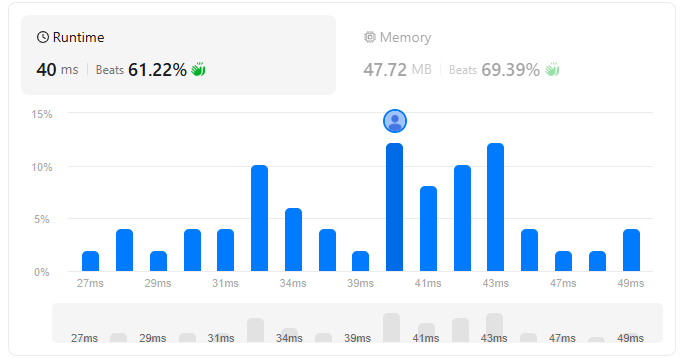